# VN30 OHLCV

Fetches OHLCV for every VN30 constituent between `START_DATE` and `END_DATE`.
Change the parameters in the next cell and re-run all.

`vnstock` (and its dependency `vnai`) are quarantined on PyPI as of 2026-10-22, so this notebook calls
the same Vietcap (VCI) endpoints vnstock's `source='VCI'` uses, directly. Needs only `pandas` + `requests`.

- Prices are **adjusted** and in **thousand VND** (same convention as vnstock).
- The VN30 list is the **current** composition, not point-in-time.

In [1]:
# ---- parameters ----
START_DATE = "2025-01-01"   # YYYY-MM-DD (inclusive)
END_DATE   = "2025-12-31"   # YYYY-MM-DD (inclusive)
INTERVAL   = "1D"           # 1D, 1H or 1m
SYMBOLS    = None           # None = current VN30 list; or e.g. ["FPT", "VCB"]
SLEEP_SEC  = 0.5            # pause between requests, be polite
OUT_FILE   = f"vn30_ohlcv_{START_DATE}_{END_DATE}_{INTERVAL}.csv"

In [2]:
import time
import pandas as pd
import requests

BASE = "https://trading.vietcap.com.vn/api"
HEADERS = {
    "User-Agent": "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0 Safari/537.36",
    "Referer": "https://trading.vietcap.com.vn/",
    "Origin": "https://trading.vietcap.com.vn",
}
TIMEFRAME = {"1D": "ONE_DAY", "1H": "ONE_HOUR", "1m": "ONE_MINUTE"}
BARS_PER_DAY = {"1D": 1, "1H": 7, "1m": 300}   # upper bounds for the countBack window

In [3]:
def vn30_symbols():
    r = requests.get(f"{BASE}/price/symbols/getByGroup", params={"group": "VN30"}, headers=HEADERS, timeout=30)
    r.raise_for_status()
    return sorted(x["symbol"] for x in r.json())

symbols = vn30_symbols() if SYMBOLS is None else list(SYMBOLS)
print(len(symbols), symbols)

30 ['ACB', 'BID', 'BSR', 'CTG', 'FPT', 'GAS', 'GVR', 'HDB', 'HPG', 'LPB', 'MBB', 'MCH', 'MSN', 'MWG', 'SAB', 'SHB', 'SSB', 'SSI', 'STB', 'TCB', 'TCX', 'VCB', 'VHM', 'VIB', 'VIC', 'VJC', 'VNM', 'VPB', 'VPL', 'VRE']


In [4]:
def fetch_ohlcv(symbol, start, end, interval="1D", retries=3):
    """OHLCV for one symbol (the endpoint returns nothing if given several). Returns long DataFrame."""
    start_ts = pd.Timestamp(start, tz="Asia/Ho_Chi_Minh")
    end_ts = pd.Timestamp(end, tz="Asia/Ho_Chi_Minh") + pd.Timedelta(days=1)   # make END_DATE inclusive
    # API returns the last `countBack` bars before `to`; over-ask, then trim to START_DATE
    count_back = ((end_ts - start_ts).days + 1) * BARS_PER_DAY[interval]
    payload = {
        "timeFrame": TIMEFRAME[interval],
        "symbols": [symbol],
        "to": int(end_ts.timestamp()),
        "countBack": count_back,
    }
    for attempt in range(1, retries + 1):
        try:
            r = requests.post(f"{BASE}/chart/OHLCChart/gap-chart", json=payload, headers=HEADERS, timeout=60)
            r.raise_for_status()
            data = r.json()
            break
        except requests.RequestException as e:
            print(f"{symbol}: attempt {attempt} failed: {e}")
            if attempt == retries:
                return None
            time.sleep(5 * attempt)
    if not data or not data[0]["t"]:
        return None

    item = data[0]
    df = pd.DataFrame({
        "time": pd.to_datetime(pd.Series(item["t"], dtype="int64"), unit="s", utc=True).dt.tz_convert("Asia/Ho_Chi_Minh"),
        "open": item["o"], "high": item["h"], "low": item["l"], "close": item["c"], "volume": item["v"],
    })
    df = df[(df["time"] >= start_ts) & (df["time"] < end_ts)].copy()
    df[["open", "high", "low", "close"]] = (df[["open", "high", "low", "close"]] / 1000).round(2)   # thousand VND
    df["time"] = df["time"].dt.tz_localize(None)   # local Vietnam time
    if interval == "1D":
        df["time"] = df["time"].dt.normalize()
    df.insert(0, "symbol", symbol)
    return df

frames, failed = [], []
for i, sym in enumerate(symbols, 1):
    df = fetch_ohlcv(sym, START_DATE, END_DATE, INTERVAL)
    if df is None or df.empty:
        failed.append(sym)
    else:
        frames.append(df)
        print(f"[{i}/{len(symbols)}] {sym}: {len(df)} bars")
    time.sleep(SLEEP_SEC)

ohlcv = pd.concat(frames, ignore_index=True).sort_values(["symbol", "time"]).reset_index(drop=True)
print(f"{len(ohlcv)} rows, {ohlcv['symbol'].nunique()} symbols, failed: {failed}")
ohlcv.head()

[1/30] ACB: 249 bars
[2/30] BID: 249 bars
[3/30] BSR: 241 bars
[4/30] CTG: 249 bars
[5/30] FPT: 249 bars
[6/30] GAS: 249 bars
[7/30] GVR: 249 bars
[8/30] HDB: 249 bars
[9/30] HPG: 249 bars
[10/30] LPB: 249 bars
[11/30] MBB: 249 bars
[12/30] MCH: 244 bars
[13/30] MSN: 249 bars
[14/30] MWG: 249 bars
[15/30] SAB: 249 bars
[16/30] SHB: 249 bars
[17/30] SSB: 249 bars
[18/30] SSI: 249 bars
[19/30] STB: 249 bars
[20/30] TCB: 249 bars
[21/30] TCX: 52 bars
[22/30] VCB: 249 bars
[23/30] VHM: 249 bars
[24/30] VIB: 249 bars
[25/30] VIC: 249 bars
[26/30] VJC: 249 bars
[27/30] VNM: 249 bars
[28/30] VPB: 249 bars
[29/30] VPL: 165 bars
[30/30] VRE: 249 bars
7176 rows, 30 symbols, failed: []


,symbol,time,open,high,low,close,volume
0,ACB,2025-01-02,18.43,18.50,18.28,18.43,4571487
1,ACB,2025-01-03,18.36,18.39,18.07,18.07,5022490
2,ACB,2025-01-06,18.00,18.03,17.82,17.85,12058848
3,ACB,2025-01-07,17.85,18.03,17.85,18.00,5028704
4,ACB,2025-01-08,18.00,18.00,17.85,18.00,4091798


In [5]:
# bars per symbol and date coverage
ohlcv.groupby("symbol")["time"].agg(["count", "min", "max"])

,count,min,max
symbol,,,
ACB,249,2025-01-02,2025-12-31
BID,249,2025-01-02,2025-12-31
BSR,241,2025-01-02,2025-12-31
CTG,249,2025-01-02,2025-12-31
FPT,249,2025-01-02,2025-12-31
GAS,249,2025-01-02,2025-12-31
GVR,249,2025-01-02,2025-12-31
HDB,249,2025-01-02,2025-12-31
HPG,249,2025-01-02,2025-12-31


In [6]:
ohlcv.to_csv(OUT_FILE, index=False)
print(f"saved {len(ohlcv)} rows -> {OUT_FILE}")

saved 7176 rows -> vn30_ohlcv_2025-01-01_2025-12-31_1D.csv


In [7]:
# wide close-price table: index = time, columns = symbol
close = ohlcv.pivot(index="time", columns="symbol", values="close")
close.tail()

symbol,ACB,BID,BSR,CTG,FPT,GAS,GVR,HDB,HPG,LPB,...,TCX,VCB,VHM,VIB,VIC,VJC,VNM,VPB,VPL,VRE
time,,,,,,,,,,,,,,,,,,,,,
2025-12-25,20.68,35.90,15.72,34.47,83.40,67.25,25.65,21.19,23.43,39.69,...,31.93,56.63,55.04,15.41,158.0,163.07,59.36,22.41,99.0,31.15
2025-12-26,20.59,35.90,16.07,34.66,82.95,68.51,25.50,21.23,24.01,39.22,...,31.93,56.63,52.96,15.24,155.0,159.92,59.55,21.94,92.1,30.91
2025-12-29,20.68,35.90,16.51,34.76,84.56,72.98,26.00,21.23,23.84,39.50,...,31.62,56.63,56.67,15.24,159.7,160.15,60.13,21.83,94.0,32.06
2025-12-30,20.76,36.45,16.02,35.11,86.54,72.79,26.60,21.50,23.66,39.60,...,31.93,56.82,56.58,15.32,163.0,157.99,59.84,22.37,91.0,31.68
2025-12-31,20.68,35.99,15.92,35.21,85.91,70.36,26.20,22.85,23.57,39.50,...,32.30,57.02,59.71,15.37,169.6,160.76,59.26,22.33,94.2,32.50


## Plot: VN30 performance, small multiples

One panel per stock, close rebased to 100 at its first bar in the window (log scale, shared axis, so panels compare directly). Grey lines in each panel are the other 29 stocks for context. Panels are sorted best to worst.

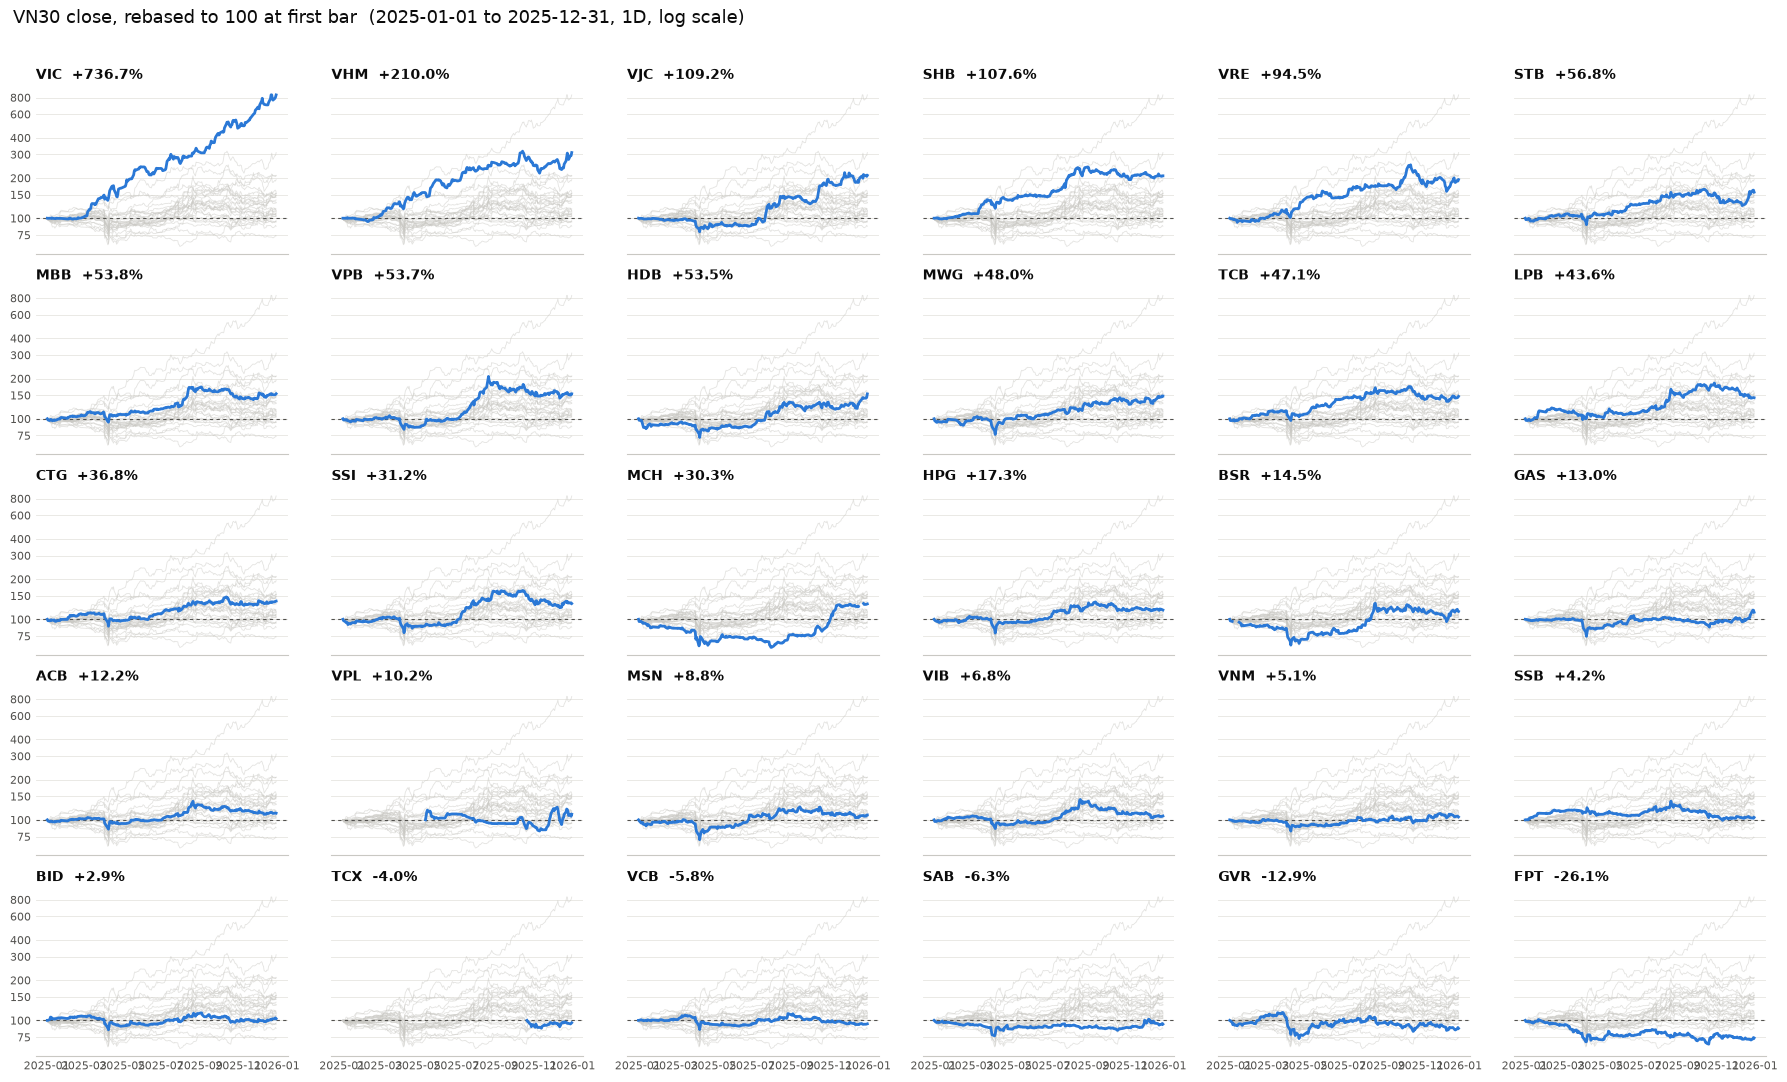

In [8]:
import math
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, NullLocator, FuncFormatter

BLUE, GREY, INK, MUTED = "#2a78d6", "#c9c8c3", "#0b0b0b", "#52514e"

# rebase each stock to 100 at its own first close in the window (TCX/VPL list mid-window)
rebased = close.apply(lambda s: s / s.dropna().iloc[0] * 100)
total_ret = rebased.apply(lambda s: s.dropna().iloc[-1] - 100).sort_values(ascending=False)

n = len(total_ret)
ncols = 6
nrows = math.ceil(n / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(3.0 * ncols, 2.2 * nrows), sharex=True, sharey=True)
axes = axes.ravel()

lo, hi = rebased.min().min(), rebased.max().max()
ticks = [t for t in (25, 50, 75, 100, 150, 200, 300, 400, 600, 800) if lo * 0.9 <= t <= hi * 1.1]

for ax, sym in zip(axes, total_ret.index):
    for other in rebased.columns.drop(sym):
        ax.plot(rebased.index, rebased[other], color=GREY, lw=0.6, alpha=0.5)
    ax.axhline(100, color=MUTED, lw=0.8, ls=(0, (3, 3)))
    ax.plot(rebased.index, rebased[sym], color=BLUE, lw=2)
    r = total_ret[sym]
    ax.set_title(f"{sym}  {r:+.1f}%", loc="left", fontsize=10, color=INK, fontweight="bold")
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(FixedLocator(ticks))
    ax.yaxis.set_minor_locator(NullLocator())
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.tick_params(colors=MUTED, labelsize=8, length=0)
    ax.grid(axis="y", color="#e6e5e0", lw=0.6)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GREY)

for ax in axes[n:]:
    ax.set_visible(False)

fig.autofmt_xdate(rotation=0, ha="center")
fig.suptitle(f"VN30 close, rebased to 100 at first bar  ({START_DATE} to {END_DATE}, {INTERVAL}, log scale)",
             x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig(f"vn30_close_{START_DATE}_{END_DATE}_{INTERVAL}.png", dpi=120, facecolor="white")
plt.show()